In [ ]:
import pandas as pd

df = pd.read_csv("ai4i.csv.zip")   # use the exact file name you uploaded
print(df.head())

   UDI Product ID Type  Air temperature [K]  Process temperature [K]  \
0    1     M14860    M                298.1                    308.6   
1    2     L47181    L                298.2                    308.7   
2    3     L47182    L                298.1                    308.5   
3    4     L47183    L                298.2                    308.6   
4    5     L47184    L                298.2                    308.7   

   Rotational speed [rpm]  Torque [Nm]  Tool wear [min]  Machine failure  TWF  \
0                    1551         42.8                0                0    0   
1                    1408         46.3                3                0    0   
2                    1498         49.4                5                0    0   
3                    1433         39.5                7                0    0   
4                    1408         40.0                9                0    0   

   HDF  PWF  OSF  RNF  
0    0    0    0    0  
1    0    0    0    0  
2    0  

# Predictive Maintenance – Fighting Alert Fatigue
### AI4I 2020 Dataset | Beginner Project
**Goal:** Reduce noisy alerts while still catching real machine failures.

In [ ]:
# 1. Basic info
print("Shape of data:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

Shape of data: (10000, 14)

Column names:
['UDI', 'Product ID', 'Type', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Machine failure', 'TWF', 'HDF', 'PWF', 'OSF', 'RNF']


## 1. Load and Explore the Data

In [ ]:
# 2. Check how many failures we have
print(df['Machine failure'].value_counts())
print("\nFailure percentage:")
print(df['Machine failure'].value_counts(normalize=True) * 100)

Machine failure
0    9661
1     339
Name: count, dtype: int64

Failure percentage:
Machine failure
0    96.61
1     3.39
Name: proportion, dtype: float64


## 2. Data Cleaning
We rename columns and keep only the useful features to make the data easier to work with.

In [ ]:
# 3. Basic statistics of important columns
print(df[['Air temperature [K]', 'Process temperature [K]',
          'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]']].describe())

       Air temperature [K]  Process temperature [K]  Rotational speed [rpm]  \
count         10000.000000             10000.000000            10000.000000   
mean            300.004930               310.005560             1538.776100   
std               2.000259                 1.483734              179.284096   
min             295.300000               305.700000             1168.000000   
25%             298.300000               308.800000             1423.000000   
50%             300.100000               310.100000             1503.000000   
75%             301.500000               311.100000             1612.000000   
max             304.500000               313.800000             2886.000000   

        Torque [Nm]  Tool wear [min]  
count  10000.000000     10000.000000  
mean      39.986910       107.951000  
std        9.968934        63.654147  
min        3.800000         0.000000  
25%       33.200000        53.000000  
50%       40.100000       108.000000  
75%       46.80

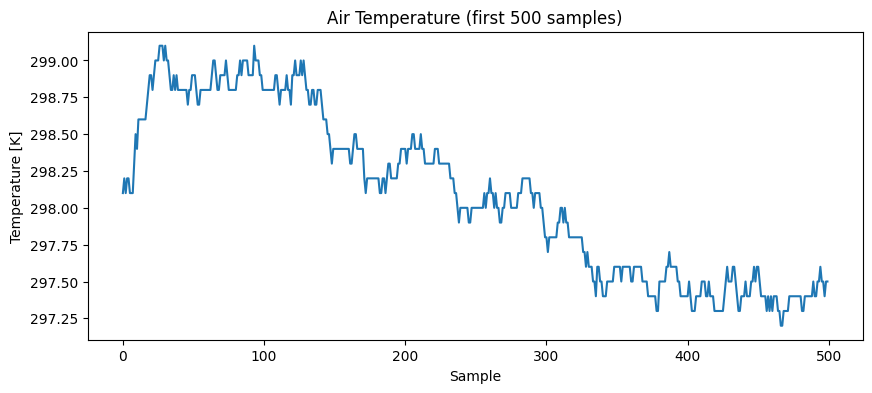

In [ ]:
# 4. Simple plot (temperature)
import matplotlib.pyplot as plt

plt.figure(figsize=(10,4))
plt.plot(df['Air temperature [K]'][:500])  # first 500 points
plt.title("Air Temperature (first 500 samples)")
plt.xlabel("Sample")
plt.ylabel("Temperature [K]")
plt.show()

In [ ]:
# Check missing values
print(df.isnull().sum())

# Check data types
print(df.dtypes)

UDI                        0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Machine failure            0
TWF                        0
HDF                        0
PWF                        0
OSF                        0
RNF                        0
dtype: int64
UDI                          int64
Product ID                  object
Type                        object
Air temperature [K]        float64
Process temperature [K]    float64
Rotational speed [rpm]       int64
Torque [Nm]                float64
Tool wear [min]              int64
Machine failure              int64
TWF                          int64
HDF                          int64
PWF                          int64
OSF                          int64
RNF                          int64
dtype: object


In [ ]:
print("Total failures:", df['Machine failure'].sum())
print(df[['TWF', 'HDF', 'PWF', 'OSF', 'RNF']].sum())

Total failures: 339
TWF     46
HDF    115
PWF     95
OSF     98
RNF     19
dtype: int64


In [ ]:
# Create a cleaner version
df_clean = df.copy()

# Rename columns for easier use
df_clean = df_clean.rename(columns={
    'Air temperature [K]': 'air_temp',
    'Process temperature [K]': 'process_temp',
    'Rotational speed [rpm]': 'speed',
    'Torque [Nm]': 'torque',
    'Tool wear [min]': 'tool_wear',
    'Machine failure': 'failure'
})

# Keep only useful columns
df_clean = df_clean[['air_temp', 'process_temp', 'speed', 'torque', 'tool_wear', 'failure', 'Type']]

print(df_clean.head())
print(df_clean.shape)

   air_temp  process_temp  speed  torque  tool_wear  failure Type
0     298.1         308.6   1551    42.8          0        0    M
1     298.2         308.7   1408    46.3          3        0    L
2     298.1         308.5   1498    49.4          5        0    L
3     298.2         308.6   1433    39.5          7        0    L
4     298.2         308.7   1408    40.0          9        0    L
(10000, 7)


In [ ]:
# Look at extreme values
print("Max air temperature:", df_clean['air_temp'].max())
print("Min air temperature:", df_clean['air_temp'].min())
print("Max torque:", df_clean['torque'].max())
print("Max tool wear:", df_clean['tool_wear'].max())

Max air temperature: 304.5
Min air temperature: 295.3
Max torque: 76.6
Max tool wear: 253


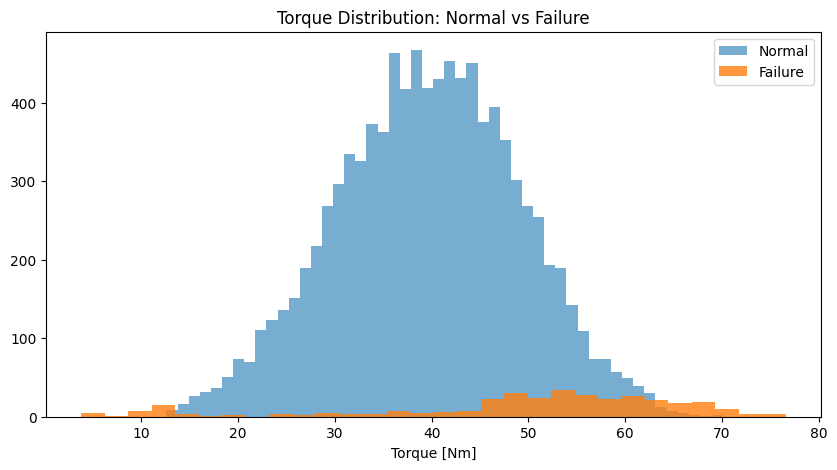

In [ ]:
import matplotlib.pyplot as plt

# Compare torque for normal vs failure
plt.figure(figsize=(10,5))
plt.hist(df_clean[df_clean['failure']==0]['torque'], bins=50, alpha=0.6, label='Normal')
plt.hist(df_clean[df_clean['failure']==1]['torque'], bins=30, alpha=0.8, label='Failure')
plt.title("Torque Distribution: Normal vs Failure")
plt.xlabel("Torque [Nm]")
plt.legend()
plt.show()

In [ ]:
# Dumb system: Alert if torque > 50 OR air_temp > 302 OR tool_wear > 150
df_clean['dumb_alert'] = (
    (df_clean['torque'] > 50) |
    (df_clean['air_temp'] > 302) |
    (df_clean['tool_wear'] > 150)
).astype(int)

print("Total Dumb Alerts:", df_clean['dumb_alert'].sum())
print("Dumb Alert percentage: {:.2f}%".format(df_clean['dumb_alert'].mean() * 100))

Total Dumb Alerts: 5198
Dumb Alert percentage: 51.98%


## 3. Alert Fatigue Demonstration

### 3.1 Dumb Alert System
Triggers an alert if any single sensor crosses a simple threshold. This creates too many alerts.

In [ ]:
# Smarter system: Only alert when multiple conditions are risky together
df_clean['smart_alert'] = (
    ((df_clean['torque'] > 50) & (df_clean['tool_wear'] > 120)) |
    ((df_clean['air_temp'] > 302) & (df_clean['process_temp'] - df_clean['air_temp'] < 9)) |
    (df_clean['tool_wear'] > 200)
).astype(int)

print("Total Smart Alerts:", df_clean['smart_alert'].sum())
print("Smart Alert percentage: {:.2f}%".format(df_clean['smart_alert'].mean() * 100))

Total Smart Alerts: 2088
Smart Alert percentage: 20.88%


### 3.2 Smart Rule-Based System
Uses multiple conditions together to reduce noise.

In [ ]:
print("\n--- Comparison ---")
print("Dumb Alerts:", df_clean['dumb_alert'].sum())
print("Smart Alerts:", df_clean['smart_alert'].sum())
print("Reduction in alerts: {:.1f}%".format(
    (1 - df_clean['smart_alert'].sum() / df_clean['dumb_alert'].sum()) * 100
))


--- Comparison ---
Dumb Alerts: 5198
Smart Alerts: 2088
Reduction in alerts: 59.8%


In [ ]:
print("\nReal failures caught by Dumb system:",
      ((df_clean['dumb_alert'] == 1) & (df_clean['failure'] == 1)).sum())

print("Real failures caught by Smart system:",
      ((df_clean['smart_alert'] == 1) & (df_clean['failure'] == 1)).sum())


Real failures caught by Dumb system: 312
Real failures caught by Smart system: 254


In [ ]:
from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler

# Select features for anomaly detection
features = ['air_temp', 'process_temp', 'speed', 'torque', 'tool_wear']
X = df_clean[features]

# Scale the data (very important)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

## 4. Machine Learning Approach (Isolation Forest)
We try a basic anomaly detection model to see how pure ML performs.

In [ ]:
# contamination = expected % of anomalies (we can start with 0.05 = 5%)
model = IsolationForest(contamination=0.05, random_state=42)
df_clean['anomaly'] = model.fit_predict(X_scaled)

# Convert to 0 and 1 (1 = anomaly)
df_clean['anomaly'] = df_clean['anomaly'].map({1: 0, -1: 1})

print("Number of anomalies detected:", df_clean['anomaly'].sum())

Number of anomalies detected: 500


In [ ]:
print("Anomalies that are real failures:",
      ((df_clean['anomaly'] == 1) & (df_clean['failure'] == 1)).sum())

print("Total real failures:", df_clean['failure'].sum())

Anomalies that are real failures: 72
Total real failures: 339


In [ ]:
print("\n--- Final Comparison ---")
print("Dumb Alerts:", df_clean['dumb_alert'].sum())
print("Smart Alerts:", df_clean['smart_alert'].sum())
print("Anomaly Detection:", df_clean['anomaly'].sum())
print()
print("Real failures caught:")
print("Dumb:", ((df_clean['dumb_alert']==1) & (df_clean['failure']==1)).sum())
print("Smart:", ((df_clean['smart_alert']==1) & (df_clean['failure']==1)).sum())
print("Anomaly:", ((df_clean['anomaly']==1) & (df_clean['failure']==1)).sum())


--- Final Comparison ---
Dumb Alerts: 5198
Smart Alerts: 2088
Anomaly Detection: 500

Real failures caught:
Dumb: 312
Smart: 254
Anomaly: 72


In [ ]:
# Hybrid Alert = Smart Rules OR (Anomaly + some risk condition)
df_clean['hybrid_alert'] = (
    (df_clean['smart_alert'] == 1) |
    ((df_clean['anomaly'] == 1) & (df_clean['tool_wear'] > 100))
).astype(int)

print("Hybrid Alerts:", df_clean['hybrid_alert'].sum())

print("\nReal failures caught by Hybrid:",
      ((df_clean['hybrid_alert'] == 1) & (df_clean['failure'] == 1)).sum())

Hybrid Alerts: 2213

Real failures caught by Hybrid: 266


## 5. Hybrid System (Rules + ML)
Combining domain rules with anomaly detection gives a better balance.

In [ ]:
print("\n========== FINAL COMPARISON ==========")
methods = {
    'Dumb': 'dumb_alert',
    'Smart Rules': 'smart_alert',
    'Isolation Forest': 'anomaly',
    'Hybrid': 'hybrid_alert'
}

for name, col in methods.items():
    total_alerts = df_clean[col].sum()
    caught = ((df_clean[col] == 1) & (df_clean['failure'] == 1)).sum()
    print(f"{name:20} | Alerts: {total_alerts:5} | Failures Caught: {caught:3}/339")


========== FINAL COMPARISON ==========
Dumb                 | Alerts:  5198 | Failures Caught: 312/339
Smart Rules          | Alerts:  2088 | Failures Caught: 254/339
Isolation Forest     | Alerts:   500 | Failures Caught:  72/339
Hybrid               | Alerts:  2213 | Failures Caught: 266/339


## 6. Final Comparison

| Method              | Total Alerts | Failures Caught |
|---------------------|--------------|-----------------|
| Dumb System         | 5198         | 312/339         |
| Smart Rules         | 2088         | 254/339         |
| Isolation Forest    | 500          | 72/339          |
| Hybrid              | 2213         | 266/339         |

**Key Learning:** Pure ML is not always best. Combining simple rules with ML works better in industrial settings.